# Sector Rotation Across Regions

VandaXasset publishes combined positioning by **GICS sector** for ten equity markets: the US, Europe, Japan, Korea,
Taiwan, China A, China H, Australia, India and the Philippines. On one grid, that answers three questions:

1. **Where is the global consensus?** Sectors crowded in every region
2. **Where do regions disagree?** The same sector long in one market and short in another, a relative-value lead
3. **Where is it rotating?** Positioning momentum by sector and region

In [1]:
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()

SECTORS = {"COMS": "Comm. Services", "DISC": "Cons. Discretionary", "STAP": "Cons. Staples", "ENER": "Energy", "FINA": "Financials",
           "HLTH": "Health Care", "INDU": "Industrials", "MATE": "Materials", "RLST": "Real Estate", "TECH": "Technology", "UTIL": "Utilities"}
REGIONS = {
    "us_equity_sector_positioning": ("US", "USEQCOMB"), "eu_equity_sector_positioning": ("Europe", "EUEQCOMB"),
    "jp_equity_sector_positioning": ("Japan", "JPEQCOMB"), "kr_equity_sector_positioning": ("Korea", "KREQCOMB"),
    "tw_equity_sector_positioning": ("Taiwan", "TWEQCOMB"), "cn_a_share_sector_positioning": ("China A", "CNEQASHRCOMB"),
    "cn_h_share_sector_positioning": ("China H", "CNEQHSHRCOMB"), "au_equity_positioning": ("Australia", "AUEQCOMB"),
    "in_equity_positioning": ("India", "INEQCOMB"), "ph_equity_positioning": ("Philippines", "PHEQCOMB"),
}

## 1. One region × sector panel

Sector series are named `<market>COMB-<SECTOR>`. Korea also publishes beta-adjusted variants (`-BETA`), which we leave
out for like-for-like comparison. Cadences differ (Japan and Australia are weekly, India bi-weekly), so everything is
put on a **weekly Friday** grid, carrying a value forward for at most three weeks.

In [2]:
frames = []
for dataset, (region, prefix) in REGIONS.items():
    df = qk.load("positioning", dataset)
    df = df[df.series_label.str.match(rf"^{prefix}-[A-Z]{{4}}$")]
    df["region"] = region
    df["sector"] = df.series_label.str[-4:].map(SECTORS)
    frames.append(df)

long_df = pd.concat(frames, ignore_index=True)
weekly = (
    long_df.pivot_table(index="ts", columns=["region", "sector"], values="value", aggfunc="last")
    .resample("W-FRI").last().ffill(limit=3)
)
coverage = long_df.groupby("region").agg(sectors=("sector", "nunique"), since=("ts", "min"), cadence=("frequency", "first"))
coverage

,sectors,since,cadence
region,,,
Australia,11,2015-01-02,weekly
China A,11,2016-06-01,daily
China H,11,2011-12-28,daily
Europe,11,2010-01-04,daily
India,11,2012-05-31,bi-weekly
Japan,11,2000-04-28,weekly
Korea,11,2015-07-31,daily
Philippines,9,2021-04-20,daily
Taiwan,11,2012-07-27,daily


## 2. Today's map

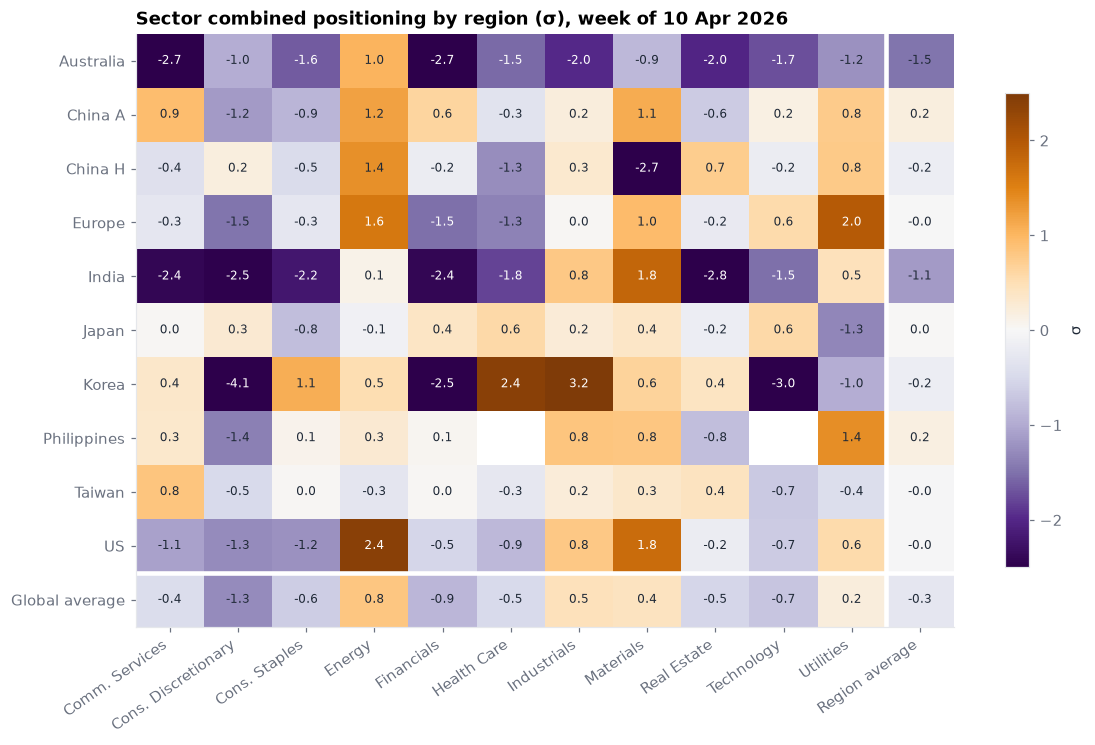

In [3]:
latest = weekly.iloc[-1].unstack("sector").reindex(columns=list(SECTORS.values()))
latest.loc["Global average"] = latest.mean()
latest["Region average"] = latest.mean(axis=1)


def grid(table: pd.DataFrame, title: str, vmax: float = 2.5, fmt: str = "{:.1f}") -> None:
    fig, ax = plt.subplots(figsize=(12, 0.5 * len(table) + 1.5))
    im = ax.imshow(table.values, cmap="PuOr_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=35, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    for (i, j), v in np.ndenumerate(table.values):
        if np.isfinite(v):
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="white" if abs(v) > vmax * 0.6 else qk.VANDA["ink"])
    ax.axhline(len(table) - 1.5, color="white", lw=3)
    ax.axvline(table.shape[1] - 1.5, color="white", lw=3)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="σ")
    ax.set_title(title)
    plt.show()


grid(latest, f"Sector combined positioning by region (σ), week of {weekly.index[-1]:%d %b %Y}")

## 3. Consensus vs disagreement

For each sector:

* **Consensus** is the average z across regions. A high value means the sector is crowded globally, and it is the
  theme most exposed to a coordinated unwind.
* **Disagreement** is the spread between the most-long and most-short region. A wide spread, with regions on opposite
  sides, is where a regional pair trade (long the under-owned market's sector, short the crowded one) has the most
  room to converge.

In [4]:
regions_only = latest.drop(index="Global average", columns="Region average")
consensus = pd.DataFrame({
    "consensus z": regions_only.mean(),
    "regions long (>0)": (regions_only > 0).sum(),
    "regions short (<0)": (regions_only < 0).sum(),
    "most long": regions_only.idxmax(),
    "max z": regions_only.max(),
    "most short": regions_only.idxmin(),
    "min z": regions_only.min(),
})
consensus["spread"] = consensus["max z"] - consensus["min z"]
consensus.sort_values("consensus z", ascending=False).round(2)

,consensus z,regions long (>0),regions short (<0),most long,max z,most short,min z,spread
sector,,,,,,,,
Energy,0.81,8,2,US,2.39,Taiwan,-0.30,2.68
Industrials,0.47,9,1,Korea,3.25,Australia,-1.99,5.24
Materials,0.43,8,2,India,1.82,China H,-2.66,4.47
Utilities,0.20,6,4,Europe,1.96,Japan,-1.32,3.28
Comm. Services,-0.44,5,5,China A,0.93,Australia,-2.67,3.61
Health Care,-0.49,2,7,Korea,2.39,India,-1.80,4.19
Real Estate,-0.54,3,7,China H,0.73,India,-2.84,3.57
Cons. Staples,-0.63,3,7,Korea,1.09,India,-2.19,3.27
Technology,-0.72,3,6,Japan,0.58,Korea,-2.99,3.57


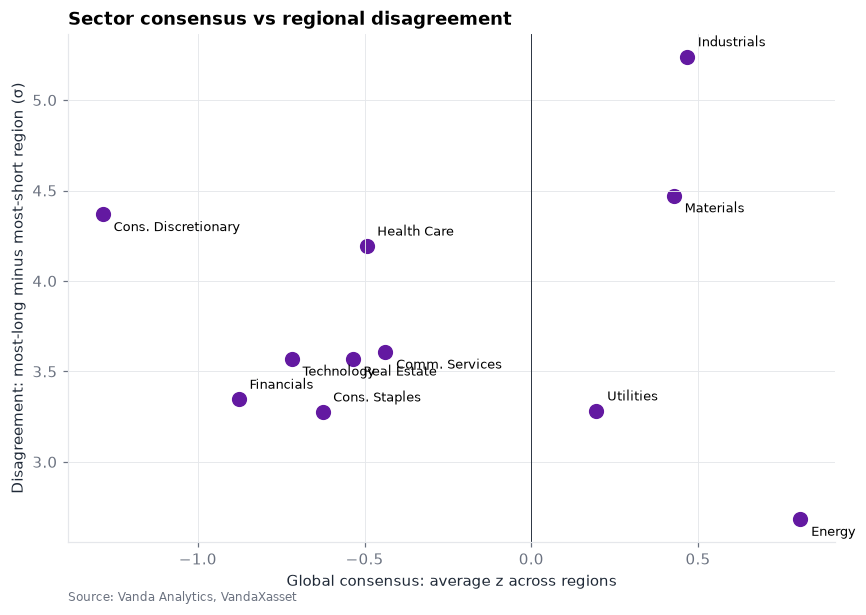

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(consensus["consensus z"], consensus["spread"], s=80, color=qk.VANDA["purple"])
for i, (sector, row) in enumerate(consensus.sort_values("consensus z").iterrows()):
    ax.annotate(sector, (row["consensus z"], row["spread"]), fontsize=8.5,
                xytext=(7, 7 if i % 2 else -11), textcoords="offset points")
ax.axvline(0, color=qk.VANDA["ink"], lw=0.6)
ax.set_xlabel("Global consensus: average z across regions")
ax.set_ylabel("Disagreement: most-long minus most-short region (σ)")
ax.set_title("Sector consensus vs regional disagreement")
qk.source_note(ax)
plt.show()

## 4. Rotation: 3-month change in positioning

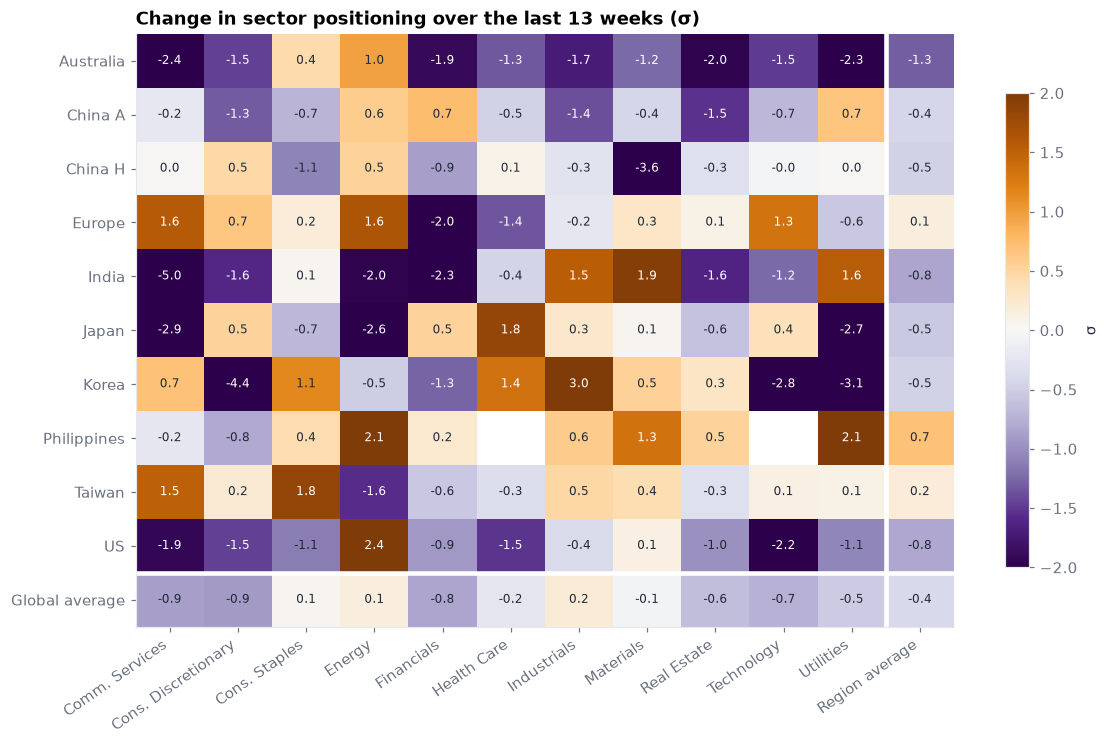

In [6]:
change = (weekly.iloc[-1] - weekly.iloc[-14]).unstack("sector").reindex(columns=list(SECTORS.values()))
change.loc["Global average"] = change.mean()
change["Region average"] = change.mean(axis=1)
grid(change, "Change in sector positioning over the last 13 weeks (σ)", vmax=2.0)

Look for **agreement between level and change**: sectors crowded *and* still being added (consensus building), and
crowded but now being cut (unwinding, the higher-risk combination flagged in notebook 03).

In [7]:
level_change = pd.DataFrame({"level": regions_only.stack(), "change_13w": change.drop(index="Global average", columns="Region average").stack()}).dropna()
crowded = level_change[level_change.level.abs() > 1].copy()
crowded["state"] = np.where(np.sign(crowded.change_13w) == np.sign(crowded.level), "building", "unwinding")
crowded["toward_neutral"] = -np.sign(crowded.level) * crowded.change_13w
print("Every region-sector cell beyond ±1σ, most-unwinding first:")
crowded.sort_values("toward_neutral", ascending=False).drop(columns="toward_neutral").round(2)

Every region-sector cell beyond ±1σ, most-unwinding first:


level  change_13w      state
region      sector                                           
Europe      Cons. Discretionary  -1.47        0.65  unwinding
            Utilities             1.96       -0.55  unwinding
Australia   Cons. Staples        -1.64        0.45  unwinding
China A     Materials             1.10       -0.43  unwinding
China H     Health Care          -1.27        0.09  unwinding
India       Cons. Staples        -2.19        0.06  unwinding
US          Materials             1.76        0.11   building
India       Health Care          -1.80       -0.45   building
China H     Energy                1.36        0.52   building
China A     Energy                1.20        0.59   building
Philippines Cons. Discretionary  -1.38       -0.80   building
Australia   Energy                1.02        0.96   building
US          Cons. Staples        -1.23       -1.11   building
Korea       Cons. Staples         1.09        1.15   building
India       Technology           -1.51       -1.24   building
Korea       Financials           -2.49       -1.28   building
China A     Cons. Discretionary  -1.15       -1.32   building
Australia   Health Care          -1.55       -1.34   building
Europe      Health Care          -1.35       -1.35   building
Korea       Health Care           2.39        1.36   building
US          Cons. Discretionary  -1.28       -1.45   building
Australia   Technology           -1.72       -1.50   building
India       Cons. Discretionary  -2.47       -1.60   building
Europe      Energy                1.61        1.64   building
India       Real Estate          -2.84       -1.64   building
Australia   Industrials          -1.99       -1.71   building
            Financials           -2.71       -1.89   building
US          Comm. Services       -1.08       -1.91   building
India       Materials             1.82        1.95   building
Australia   Real Estate          -2.03       -1.96   building
Europe      Financials           -1.52       -2.03   building
Philippines Utilities             1.37        2.08   building
Australia   Utilities            -1.22       -2.31   building
India       Financials           -2.42       -2.34   building
US          Energy                2.39        2.35   building
Australia   Comm. Services       -2.67       -2.42   building
Japan       Utilities            -1.32       -2.65   building
Korea       Technology           -2.99       -2.84   building
            Industrials           3.25        3.02   building
China H     Materials            -2.66       -3.59   building
Korea       Cons. Discretionary  -4.09       -4.40   building
India       Comm. Services       -2.42       -5.02   building

---
**That's the tour.** For live data, return to notebook 01, or connect your AI assistant to VandaXasset through the Vanda
MCP connector ([docs](https://docs.vanda-analytics.com/vanda-xasset-mcp)).